In [2]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, silhouette_score)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, AdaBoostClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

In [3]:
df_raw = pd.read_csv(r"D:\tasks\diabetes_patients_10000_full.csv")
print("Shape:", df_raw.shape)
df_raw.head()

Shape: (10000, 10)


,Patient_ID,Age,Gender,Blood_Sugar_Level,Creatinine,BMI,Urea,Cholesterol,HbA1c,Class
0,1,60.0,Male,96.0,1.34,22.5,23.0,176.0,8.6,Diabetic
1,2,77.0,Male,241.0,1.02,19.0,28.0,209.0,7.5,Diabetic
2,3,21.0,Male,229.0,1.02,25.9,32.0,151.0,9.1,Diabetic
3,4,30.0,Female,177.0,0.88,22.1,36.0,176.0,5.1,Diabetic
4,5,26.0,Female,178.0,1.20,31.8,44.0,287.0,5.2,Diabetic


In [4]:
df_raw.info()
print("Duplicated rows:", df_raw.duplicated().sum())
df_raw.describe().T

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         10000 non-null  int64  
 1   Age                9986 non-null   float64
 2   Gender             9960 non-null   str    
 3   Blood_Sugar_Level  9947 non-null   float64
 4   Creatinine         9944 non-null   float64
 5   BMI                9949 non-null   float64
 6   Urea               9949 non-null   float64
 7   Cholesterol        9968 non-null   float64
 8   HbA1c              10000 non-null  float64
 9   Class              10000 non-null  str    
dtypes: float64(7), int64(1), str(2)
memory usage: 781.4 KB
Duplicated rows: 0


,count,mean,std,min,25%,50%,75%,max
Patient_ID,10000.0,5000.500000,2886.895680,1.0,2500.75,5000.5,7500.25,10000.0
Age,9986.0,49.957240,17.630097,20.0,35.00,50.0,65.00,80.0
Blood_Sugar_Level,9947.0,169.255454,46.059059,90.0,130.00,169.0,209.00,250.0
Creatinine,9944.0,1.100253,0.286964,0.6,0.85,1.1,1.35,1.6
BMI,9949.0,26.746959,4.787215,18.5,22.60,26.7,31.00,35.0
Urea,9949.0,35.121520,11.829985,15.0,25.00,35.0,45.00,55.0
Cholesterol,9968.0,225.311196,43.806703,150.0,187.00,225.0,263.00,300.0
HbA1c,10000.0,7.503780,1.743745,4.5,6.00,7.5,9.00,10.5


Missing target values: 0


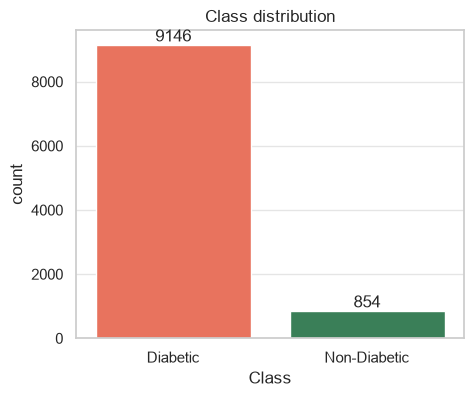

Class
Diabetic        91.46
Non-Diabetic     8.54
Name: proportion, dtype: float64
Accuracy of always predicting the majority class: 0.9146


In [5]:
print("Missing target values:", df_raw["Class"].isnull().sum())

plt.figure(figsize=(5, 4))
ax = sns.countplot(data=df_raw, x="Class", order=["Diabetic", "Non-Diabetic"], palette=["tomato", "seagreen"])
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")
plt.title("Class distribution")
plt.show()

print((df_raw["Class"].value_counts(normalize=True) * 100).round(2))
print("Accuracy of always predicting the majority class:",
      round(df_raw["Class"].value_counts(normalize=True).max(), 4))

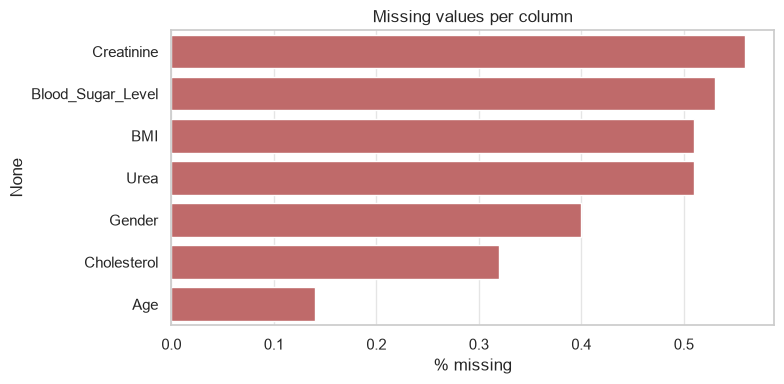

,missing %,count
Creatinine,0.56,56
Blood_Sugar_Level,0.53,53
BMI,0.51,51
Urea,0.51,51
Gender,0.40,40
Cholesterol,0.32,32
Age,0.14,14


In [6]:
miss = df_raw.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)
miss_pct = (miss / len(df_raw) * 100).round(2)

plt.figure(figsize=(8, 4))
sns.barplot(x=miss_pct.values, y=miss_pct.index, color="indianred")
plt.xlabel("% missing")
plt.title("Missing values per column")
plt.tight_layout()
plt.show()

miss_pct.to_frame("missing %").assign(count=miss)

In [7]:
df = df_raw.copy()

df = df.drop(columns="Patient_ID", errors="ignore")
df = df.drop_duplicates()

df = df[df["Class"].notna()].copy()
df["Class"] = (df["Class"].str.strip().str.lower() == "diabetic").astype(int)

df["Gender"] = df["Gender"].str.strip().str.lower().map({"male": 1, "female": 0})

df = df.reset_index(drop=True)
print("Shape after cleaning:", df.shape)
print(df["Class"].value_counts().rename({1: "Diabetic (1)", 0: "Non-Diabetic (0)"}))
df.isnull().sum()[df.isnull().sum() > 0]

Shape after cleaning: (10000, 9)
Class
Diabetic (1)        9146
Non-Diabetic (0)     854
Name: count, dtype: int64


Age                  14
Gender               40
Blood_Sugar_Level    53
Creatinine           56
BMI                  51
Urea                 51
Cholesterol          32
dtype: int64

In [8]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Diabetic share in train:", round(y_train.mean(), 4), "| in test:", round(y_test.mean(), 4))

Train: (8000, 8) | Test: (2000, 8)
Diabetic share in train: 0.9146 | in test: 0.9145


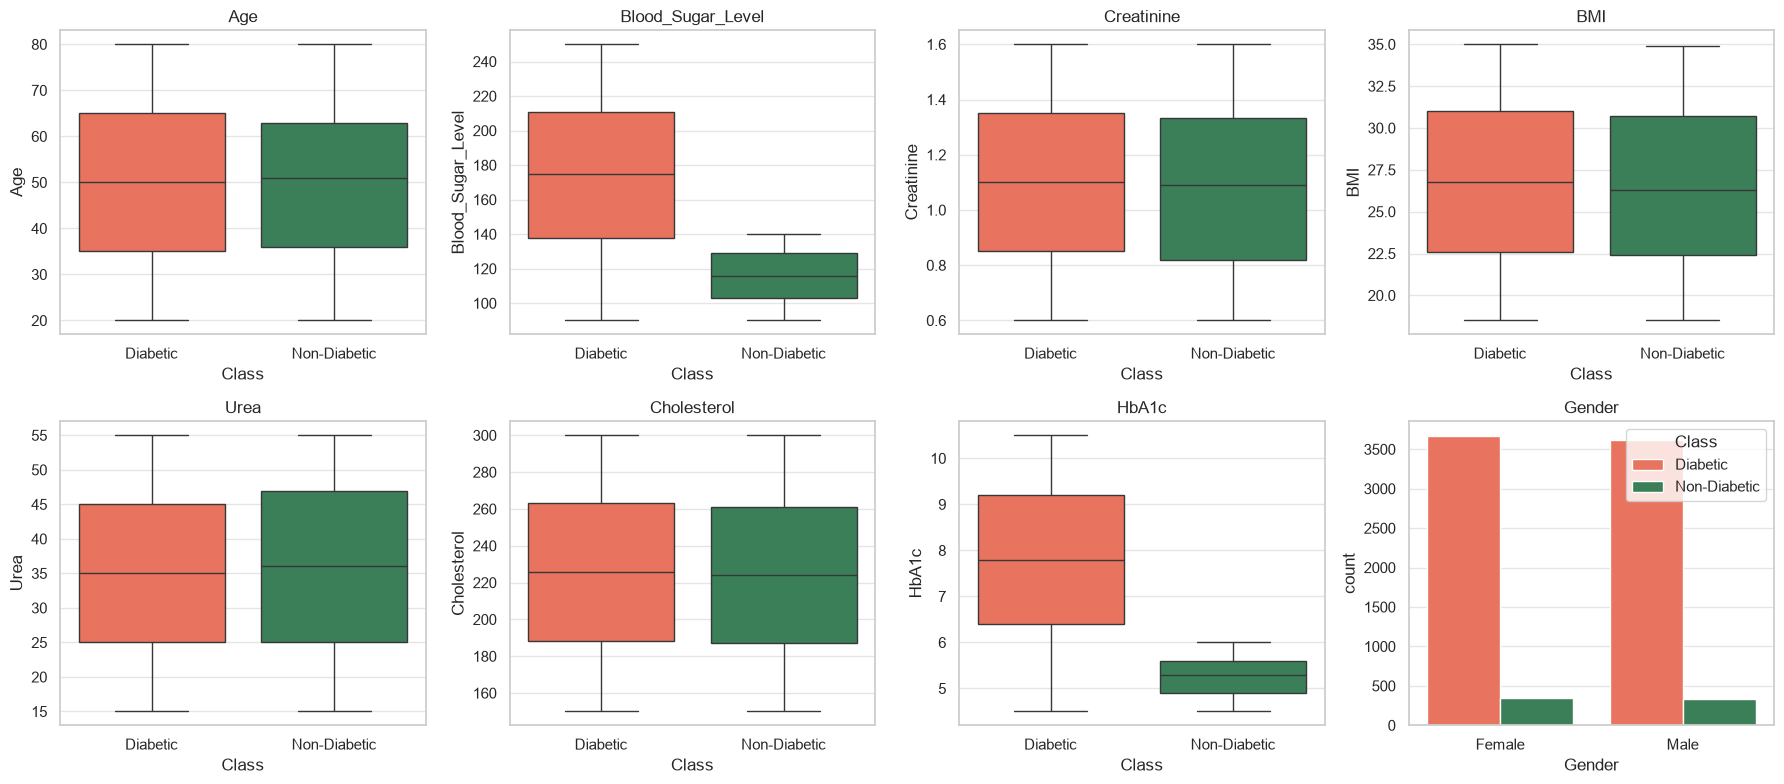

In [9]:
train_df = X_train.copy()
train_df["Class"] = y_train.map({1: "Diabetic", 0: "Non-Diabetic"})
num_features = ["Age", "Blood_Sugar_Level", "Creatinine", "BMI", "Urea", "Cholesterol", "HbA1c"]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.ravel(), num_features):
    sns.boxplot(data=train_df, x="Class", y=c, order=["Diabetic", "Non-Diabetic"],
                palette=["tomato", "seagreen"], ax=ax)
    ax.set_title(c)
gender_rate = train_df.assign(Gender=train_df["Gender"].map({1: "Male", 0: "Female"})).dropna(subset=["Gender"])
sns.countplot(data=gender_rate, x="Gender", hue="Class", hue_order=["Diabetic", "Non-Diabetic"],
              palette=["tomato", "seagreen"], ax=axes[1, 3])
axes[1, 3].set_title("Gender")
plt.tight_layout()
plt.show()

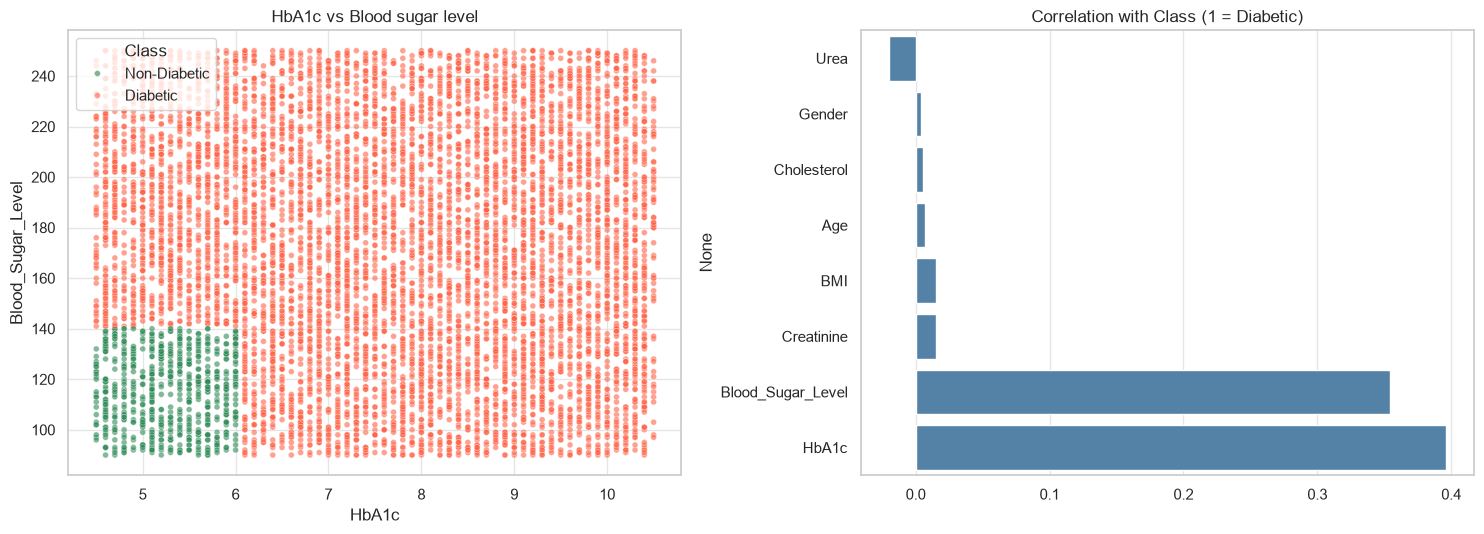

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.scatterplot(data=train_df, x="HbA1c", y="Blood_Sugar_Level", hue="Class",
                hue_order=["Non-Diabetic", "Diabetic"], palette=["seagreen", "tomato"],
                alpha=0.6, s=18, ax=axes[0])
axes[0].set_title("HbA1c vs Blood sugar level")

corr = X_train.assign(Class=y_train).corr()["Class"].drop("Class").sort_values()
sns.barplot(x=corr.values, y=corr.index, color="steelblue", ax=axes[1])
axes[1].set_title("Correlation with Class (1 = Diabetic)")

plt.tight_layout()
plt.show()

In [11]:
q1 = X_train[num_features].quantile(0.25)
q3 = X_train[num_features].quantile(0.75)
iqr = q3 - q1
outside = ((X_train[num_features] < q1 - 1.5 * iqr) | (X_train[num_features] > q3 + 1.5 * iqr)).sum()
outside.to_frame("rows outside 1.5 x IQR")

,rows outside 1.5 x IQR
Age,0
Blood_Sugar_Level,0
Creatinine,0
BMI,0
Urea,0
Cholesterol,0
HbA1c,0


In [12]:
def make_preprocessor(X):
    num_cols = X.select_dtypes(include="number").columns.tolist()
    num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler())])
    return ColumnTransformer([("num", num_pipe, num_cols)])

preprocessor = make_preprocessor(X_train)

Xt = clone(preprocessor).fit_transform(X_train)
print("Shape after preprocessing:", Xt.shape)
print("Remaining NaN:", np.isnan(Xt).sum())

Shape after preprocessing: (8000, 8)
Remaining NaN: 0


In [13]:
models = {
    "Logistic Regression":  LogisticRegression(max_iter=2000, class_weight="balanced"),
    "KNN":                  KNeighborsClassifier(n_neighbors=15),
    "SVC (RBF)":            SVC(class_weight="balanced"),
    "Naive Bayes":          GaussianNB(),
    "Neural Network (MLP)": MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                          max_iter=500, random_state=RANDOM_STATE),
    "Decision Tree":        DecisionTreeClassifier(max_depth=6, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest":        RandomForestClassifier(n_estimators=200, class_weight="balanced_subsample",
                                                   n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees":          ExtraTreesClassifier(n_estimators=200, class_weight="balanced",
                                                 n_jobs=-1, random_state=RANDOM_STATE),
    "AdaBoost":             AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE),
    "Gradient Boosting":    GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, max_depth=3,
                                                       subsample=0.8, random_state=RANDOM_STATE),
    "HistGradientBoosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}
if XGBClassifier is not None:
    models["XGBoost"] = XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
                                      colsample_bytree=0.8, random_state=RANDOM_STATE, n_jobs=-1)
if LGBMClassifier is not None:
    models["LightGBM"] = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=15, subsample=0.8,
                                        colsample_bytree=0.8, class_weight="balanced",
                                        random_state=RANDOM_STATE, verbose=-1)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted, scores, preds = [], {}, {}, {}

for name, model in models.items():
    t0 = time.time()
    pipe = Pipeline([("prep", clone(preprocessor)), ("model", model)])

    cv_bal = cross_val_score(pipe, X_train, y_train, cv=skf, scoring="balanced_accuracy", n_jobs=1).mean()

    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    score = pipe.predict_proba(X_test)[:, 1] if hasattr(pipe, "predict_proba") else pipe.decision_function(X_test)

    fitted[name], scores[name], preds[name] = pipe, score, pred
    rows.append({
        "Model": name,
        "CV Balanced Acc": cv_bal,
        "Accuracy": accuracy_score(y_test, pred),
        "Balanced Acc": balanced_accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "Macro F1": f1_score(y_test, pred, average="macro"),
        "ROC-AUC": roc_auc_score(y_test, score),
        "Time (s)": time.time() - t0,
    })
    print(f"{name:<22} Macro F1 = {rows[-1]['Macro F1']:.4f}   AUC = {rows[-1]['ROC-AUC']:.4f}   ({rows[-1]['Time (s)']:.1f}s)")

results = (pd.DataFrame(rows)
           .sort_values(["Macro F1", "ROC-AUC"], ascending=False)
           .reset_index(drop=True))
results.round(4)

Logistic Regression    Macro F1 = 0.8532   AUC = 0.9900   (0.5s)
KNN                    Macro F1 = 0.8541   AUC = 0.9883   (1.9s)
SVC (RBF)              Macro F1 = 0.8872   AUC = 0.9948   (5.2s)
Naive Bayes            Macro F1 = 0.9497   AUC = 0.9985   (0.3s)
Neural Network (MLP)   Macro F1 = 0.9535   AUC = 0.9979   (15.3s)
Decision Tree          Macro F1 = 0.9984   AUC = 0.9971   (0.4s)
Random Forest          Macro F1 = 0.9984   AUC = 1.0000   (14.4s)
Extra Trees            Macro F1 = 0.9644   AUC = 0.9995   (7.1s)
AdaBoost               Macro F1 = 0.9984   AUC = 1.0000   (12.3s)
Gradient Boosting      Macro F1 = 0.9984   AUC = 1.0000   (16.6s)
HistGradientBoosting   Macro F1 = 0.9984   AUC = 1.0000   (3.1s)
XGBoost                Macro F1 = 0.9984   AUC = 1.0000   (4.4s)
LightGBM               Macro F1 = 0.9984   AUC = 1.0000   (2.2s)


,Model,CV Balanced Acc,Accuracy,Balanced Acc,Precision,Recall,F1,Macro F1,ROC-AUC,Time (s)
0,AdaBoost,0.9985,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,1.0000,12.3442
1,Gradient Boosting,0.9985,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,1.0000,16.6071
2,HistGradientBoosting,0.9985,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,1.0000,3.1390
3,XGBoost,0.9985,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,1.0000,4.3574
4,LightGBM,0.9985,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,1.0000,2.1598
5,Random Forest,0.9985,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,1.0000,14.3829
6,Decision Tree,0.9983,0.9995,0.9971,0.9995,1.0000,0.9997,0.9984,0.9971,0.3531
7,Extra Trees,0.9317,0.9895,0.9386,0.9886,1.0000,0.9943,0.9644,0.9995,7.0775
8,Neural Network (MLP),0.9747,0.9860,0.9367,0.9886,0.9962,0.9924,0.9535,0.9979,15.3387
9,Naive Bayes,0.9509,0.9855,0.9152,0.9844,1.0000,0.9921,0.9497,0.9985,0.2697


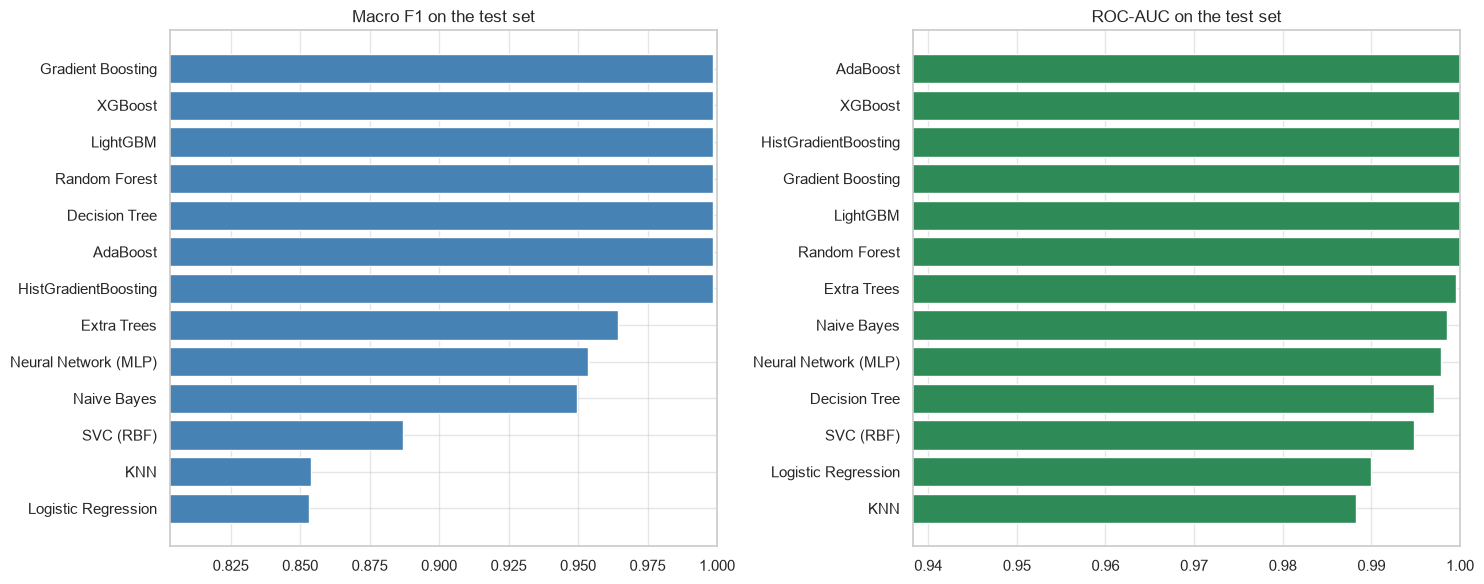

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

order = results.sort_values("Macro F1")
axes[0].barh(order["Model"], order["Macro F1"], color="steelblue")
axes[0].set_xlim(max(0, order["Macro F1"].min() - 0.05), 1.0)
axes[0].set_title("Macro F1 on the test set")

order = results.sort_values("ROC-AUC")
axes[1].barh(order["Model"], order["ROC-AUC"], color="seagreen")
axes[1].set_xlim(max(0.5, order["ROC-AUC"].min() - 0.05), 1.0)
axes[1].set_title("ROC-AUC on the test set")

plt.tight_layout()
plt.show()

## 9. Best model analysis

In [15]:
best_name = results.loc[0, "Model"]
print("Best model (Macro F1):", best_name)
print(results.loc[0].drop("Model").astype(float).round(4).to_string())
print()
print(classification_report(y_test, preds[best_name], target_names=["Non-Diabetic", "Diabetic"], digits=4))

Best model (Macro F1): AdaBoost
CV Balanced Acc     0.9985
Accuracy            0.9995
Balanced Acc        0.9971
Precision           0.9995
Recall              1.0000
F1                  0.9997
Macro F1            0.9984
ROC-AUC             1.0000
Time (s)           12.3442

              precision    recall  f1-score   support

Non-Diabetic     1.0000    0.9942    0.9971       171
    Diabetic     0.9995    1.0000    0.9997      1829

    accuracy                         0.9995      2000
   macro avg     0.9997    0.9971    0.9984      2000
weighted avg     0.9995    0.9995    0.9995      2000



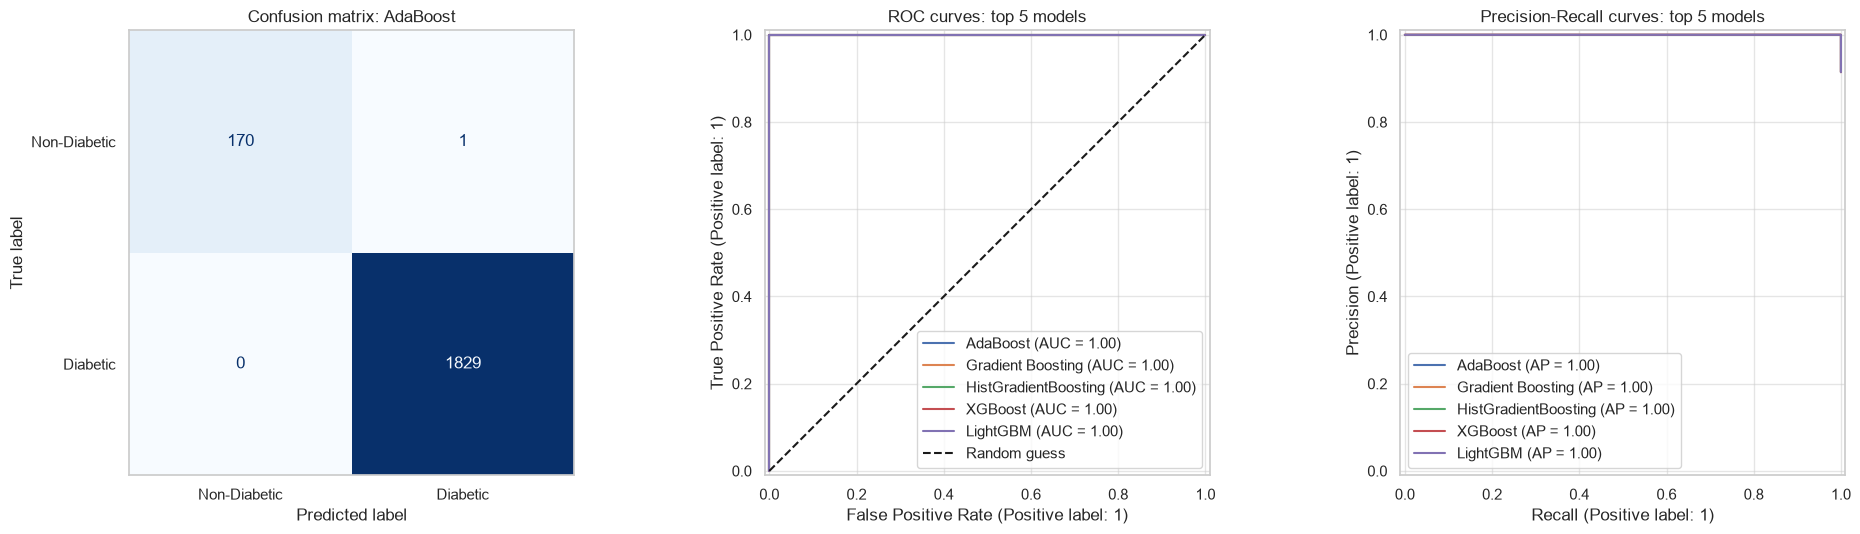

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))

ConfusionMatrixDisplay.from_predictions(y_test, preds[best_name], display_labels=["Non-Diabetic", "Diabetic"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion matrix: {best_name}")
axes[0].grid(False)

top5 = results["Model"].head(5)
for name in top5:
    RocCurveDisplay.from_predictions(y_test, scores[name], name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", label="Random guess")
axes[1].set_title("ROC curves: top 5 models")
axes[1].legend(loc="lower right")

for name in top5:
    PrecisionRecallDisplay.from_predictions(y_test, scores[name], name=name, ax=axes[2])
axes[2].set_title("Precision-Recall curves: top 5 models")
axes[2].legend(loc="lower left")

plt.tight_layout()
plt.show()

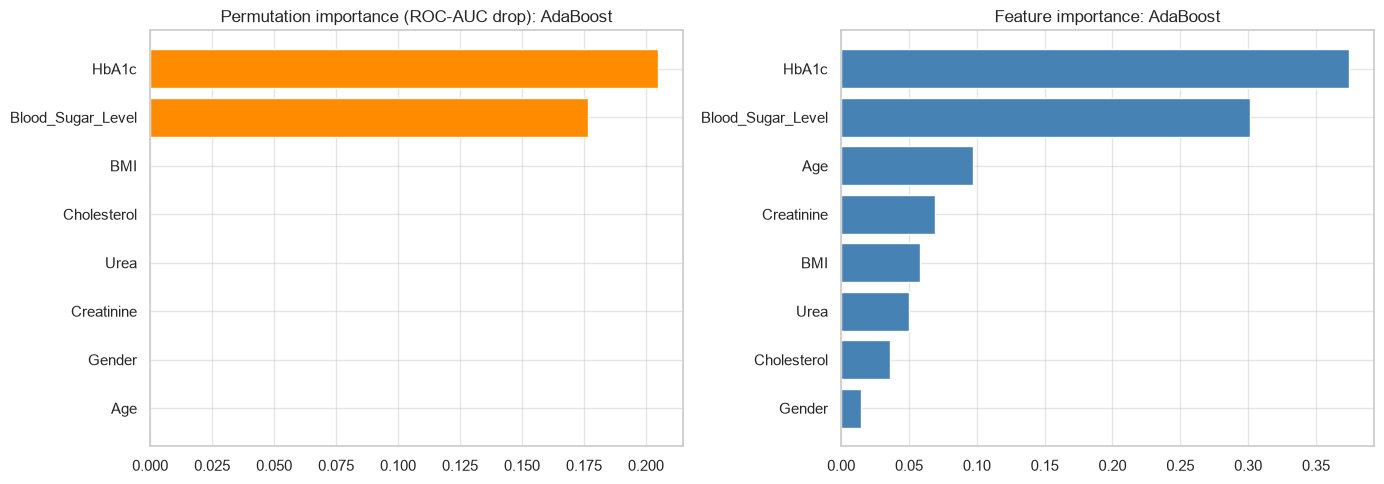

In [17]:
perm = permutation_importance(fitted[best_name], X_test, y_test, scoring="roc_auc",
                              n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()

tree_names = [n for n in results["Model"]
              if hasattr(fitted[n].named_steps["model"], "feature_importances_")]
best_tree = tree_names[0]
feat_names = fitted[best_tree].named_steps["prep"].get_feature_names_out()
tree_imp = pd.Series(fitted[best_tree].named_steps["model"].feature_importances_,
                     index=[n.split("__")[-1] for n in feat_names]).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(perm_imp.index, perm_imp.values, color="darkorange")
axes[0].set_title(f"Permutation importance (ROC-AUC drop): {best_name}")
axes[1].barh(tree_imp.index, tree_imp.values, color="steelblue")
axes[1].set_title(f"Feature importance: {best_tree}")
plt.tight_layout()
plt.show()

In [18]:
param_dist = {
    "model__n_estimators":     [100, 200, 300],
    "model__learning_rate":    [0.03, 0.05, 0.1],
    "model__max_depth":        [2, 3, 4, 5],
    "model__subsample":        [0.7, 0.85, 1.0],
    "model__min_samples_leaf": [1, 5, 10],
}

gb_pipe = Pipeline([("prep", clone(preprocessor)),
                    ("model", GradientBoostingClassifier(random_state=RANDOM_STATE))])

search = RandomizedSearchCV(gb_pipe, param_dist, n_iter=10, cv=3, scoring="f1_macro",
                            random_state=RANDOM_STATE, n_jobs=-1)
search.fit(X_train, y_train)
print("Best parameters:", search.best_params_)

tuned_pred = search.predict(X_test)
tuned_proba = search.predict_proba(X_test)[:, 1]
base = results[results["Model"] == "Gradient Boosting"].iloc[0]

pd.DataFrame({
    "Model": ["Gradient Boosting (default)", "Gradient Boosting (tuned)"],
    "Macro F1": [base["Macro F1"], f1_score(y_test, tuned_pred, average="macro")],
    "ROC-AUC": [base["ROC-AUC"], roc_auc_score(y_test, tuned_proba)],
}).round(4)

Best parameters: {'model__subsample': 0.7, 'model__n_estimators': 300, 'model__min_samples_leaf': 10, 'model__max_depth': 2, 'model__learning_rate': 0.05}


,Model,Macro F1,ROC-AUC
0,Gradient Boosting (default),0.9984,1.0
1,Gradient Boosting (tuned),0.9984,1.0


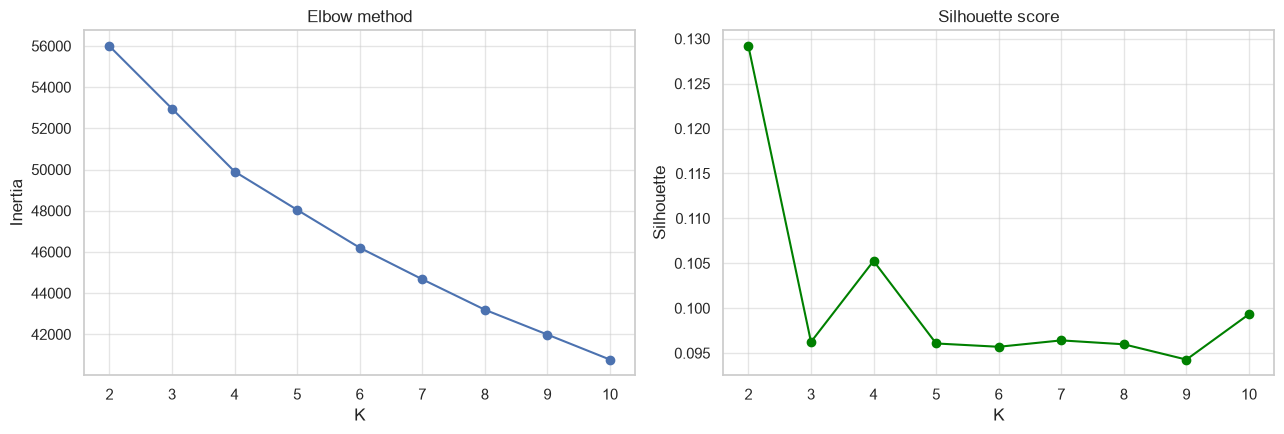

Highest silhouette at K = 2


In [19]:
Xk = clone(preprocessor).fit_transform(X_train)

ks = list(range(2, 11))
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xk)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xk, km.labels_, sample_size=3000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertias, "o-")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")
axes[1].plot(ks, sils, "o-", color="green")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
plt.tight_layout()
plt.show()

best_k = ks[int(np.argmax(sils))]
print("Highest silhouette at K =", best_k)

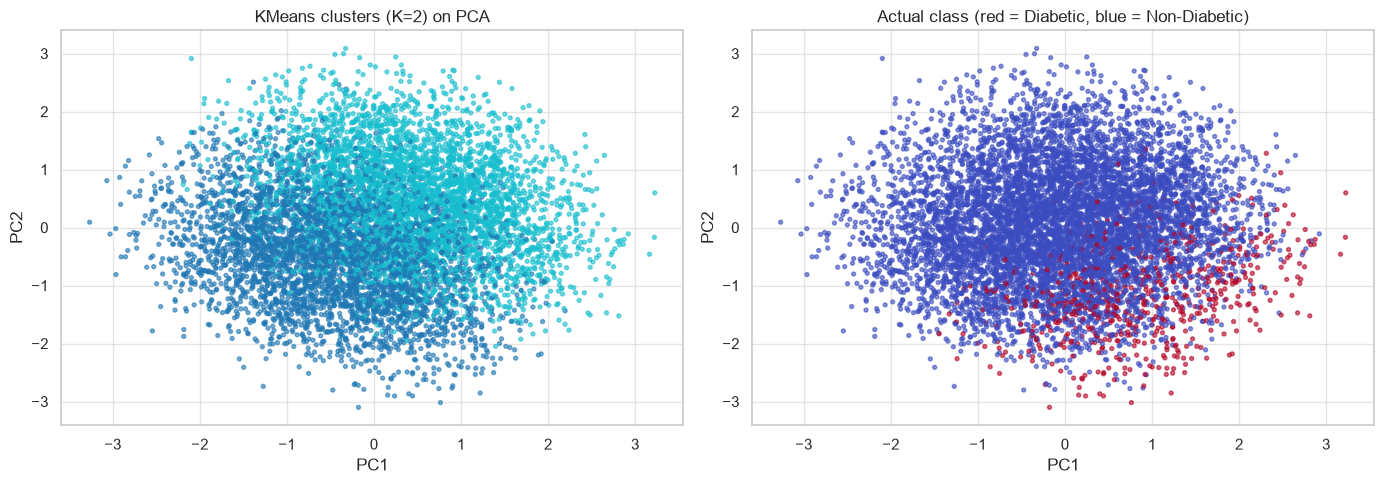

,Diabetic rate,size
0,0.916,3953
1,0.914,4047


In [20]:
km = KMeans(n_clusters=best_k, n_init=10, random_state=RANDOM_STATE).fit(Xk)
pts = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xk)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pts[:, 0], pts[:, 1], c=km.labels_, cmap="tab10", s=8, alpha=0.6)
axes[0].set_title(f"KMeans clusters (K={best_k}) on PCA")
axes[1].scatter(pts[:, 0], pts[:, 1], c=y_train, cmap="coolwarm_r", s=8, alpha=0.6)
axes[1].set_title("Actual class (red = Diabetic, blue = Non-Diabetic)")
for a in axes:
    a.set_xlabel("PC1")
    a.set_ylabel("PC2")
plt.tight_layout()
plt.show()

(pd.Series(y_train.values).groupby(km.labels_).mean().round(3).to_frame("Diabetic rate")
   .assign(size=pd.Series(km.labels_).value_counts().sort_index()))

In [21]:
r = results.loc[0]
print("=" * 70)
print(f"Best model (Macro F1): {r['Model']}")
print(f"Accuracy = {r['Accuracy']:.4f} | Balanced Acc = {r['Balanced Acc']:.4f} | Precision = {r['Precision']:.4f} | "
      f"Recall = {r['Recall']:.4f} | F1 = {r['F1']:.4f} | Macro F1 = {r['Macro F1']:.4f} | AUC = {r['ROC-AUC']:.4f}")
print("=" * 70)
print()
for i, r in results.iterrows():
    print(f"{i + 1:>2}. {r['Model']:<22} Macro F1 = {r['Macro F1']:.4f}   AUC = {r['ROC-AUC']:.4f}")

Best model (Macro F1): AdaBoost
Accuracy = 0.9995 | Balanced Acc = 0.9971 | Precision = 0.9995 | Recall = 1.0000 | F1 = 0.9997 | Macro F1 = 0.9984 | AUC = 1.0000

 1. AdaBoost               Macro F1 = 0.9984   AUC = 1.0000
 2. Gradient Boosting      Macro F1 = 0.9984   AUC = 1.0000
 3. HistGradientBoosting   Macro F1 = 0.9984   AUC = 1.0000
 4. XGBoost                Macro F1 = 0.9984   AUC = 1.0000
 5. LightGBM               Macro F1 = 0.9984   AUC = 1.0000
 6. Random Forest          Macro F1 = 0.9984   AUC = 1.0000
 7. Decision Tree          Macro F1 = 0.9984   AUC = 0.9971
 8. Extra Trees            Macro F1 = 0.9644   AUC = 0.9995
 9. Neural Network (MLP)   Macro F1 = 0.9535   AUC = 0.9979
10. Naive Bayes            Macro F1 = 0.9497   AUC = 0.9985
11. SVC (RBF)              Macro F1 = 0.8872   AUC = 0.9948
12. KNN                    Macro F1 = 0.8541   AUC = 0.9883
13. Logistic Regression    Macro F1 = 0.8532   AUC = 0.9900


In [22]:
import gradio as gr

deployment_model = fitted[best_name]
feature_columns = X_train.columns.tolist()
defaults = X_train.median()

def predict_diabetes(age, gender, sugar, creatinine, bmi, urea, cholesterol, hba1c):
    row = {
        "Age": age,
        "Gender": {"Male": 1, "Female": 0}.get(gender, np.nan),
        "Blood_Sugar_Level": sugar,
        "Creatinine": creatinine,
        "BMI": bmi,
        "Urea": urea,
        "Cholesterol": cholesterol,
        "HbA1c": hba1c,
    }
    row = {k: (np.nan if v is None else v) for k, v in row.items()}

    input_data = pd.DataFrame([row])[feature_columns]

    prediction = int(deployment_model.predict(input_data)[0])
    verdict = "Diabetic" if prediction == 1 else "Non-Diabetic"

    if hasattr(deployment_model, "predict_proba"):
        proba = deployment_model.predict_proba(input_data)[0]
        return verdict, {"Diabetic": float(proba[1]), "Non-Diabetic": float(proba[0])}
    return verdict, {verdict: 1.0}

clean_test = X_test.assign(Class=y_test).dropna()

def to_example(r):
    return [float(r["Age"]), "Male" if r["Gender"] == 1 else "Female",
            float(r["Blood_Sugar_Level"]), float(r["Creatinine"]), float(r["BMI"]),
            float(r["Urea"]), float(r["Cholesterol"]), float(r["HbA1c"])]

example_diabetic = to_example(clean_test[clean_test["Class"] == 1].iloc[0])
example_healthy = to_example(clean_test[clean_test["Class"] == 0].iloc[0])

demo = gr.Interface(
    fn=predict_diabetes,
    inputs=[
        gr.Number(value=float(defaults["Age"]), label="Age"),
        gr.Dropdown(choices=["Male", "Female"], value="Male", label="Gender"),
        gr.Number(value=float(defaults["Blood_Sugar_Level"]), label="Blood Sugar Level"),
        gr.Number(value=float(defaults["Creatinine"]), label="Creatinine"),
        gr.Number(value=float(defaults["BMI"]), label="BMI"),
        gr.Number(value=float(defaults["Urea"]), label="Urea"),
        gr.Number(value=float(defaults["Cholesterol"]), label="Cholesterol"),
        gr.Number(value=float(defaults["HbA1c"]), label="HbA1c"),
    ],
    outputs=[
        gr.Textbox(label="Prediction"),
        gr.Label(label="Probabilities", num_top_classes=2),
    ],
    examples=[example_diabetic, example_healthy],
    title="Diabetes Classification",
    description=f"Model: {best_name}. Enter the patient's data to predict the diabetes class. Empty fields are filled with the training median. For educational use only, not a medical diagnosis.",
)

demo.launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.
